Develop automated report generation pipelines using Python and libraries like Jinja2 or Pandas-Profiling, integrating model evaluation outputs and visualizations into templated documents or dashboards.

In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

In [3]:
np.random.seed(42)
X_num, y = make_classification(
    n_samples=2000, n_features=5, n_informative=4, n_redundant=1, random_state=42
)

In [4]:
df = pd.DataFrame(X_num, columns=['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose'])
df['admission_type'] = np.random.choice(['Emergency', 'Elective', 'Urgent'], size=2000, p=[0.5, 0.3, 0.2])
df.loc[df.sample(frac=0.04, random_state=42).index, 'creatinine'] = np.nan

In [5]:
num_features = ['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose']
cat_features = ['admission_type']
X = df[num_features + cat_features]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [7]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_features)
])

In [8]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(max_iter=120, learning_rate=0.05, random_state=42))
])

In [9]:
pipeline.fit(X_train, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age_norm', 'troponin',
                                                   'creatinine', 'systolic_bp',
                                                   'glucose']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['admission_type'])])),
                ('classifier',
                 HistGradientBoostingClassifier(learning_rate=0.05,
                                                max_iter=120,
                                                random_state=42))])

In [10]:
import io
import base64
import matplotlib.pyplot as plt

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.inspection import permutation_importance

In [12]:
profile_rows = []
for col in num_features:
    profile_rows.append({
        "feature": col,
        "missing_pct": round(float(df[col].isna().mean() * 100), 2),
        "mean": round(float(df[col].mean()), 3),
        "std": round(float(df[col].std()), 3),
        "min": round(float(df[col].min()), 3),
        "max": round(float(df[col].max()), 3)
    })

In [13]:
probs = pipeline.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)

In [14]:
metrics_summary = {
    "accuracy": round(float(accuracy_score(y_test, preds)), 4),
    "precision": round(float(precision_score(y_test, preds)), 4),
    "recall": round(float(recall_score(y_test, preds)), 4),
    "f1_score": round(float(f1_score(y_test, preds)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, probs)), 4)
}

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

fpr, tpr, _ = roc_curve(y_test, probs)
axes[0].plot(fpr, tpr, color="#1f77b4", lw=2, label=f"AUC = {metrics_summary['roc_auc']}")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1)
axes[0].set_title("ROC Curve (Holdout Test)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle=":", alpha=0.6)

perm = permutation_importance(pipeline, X_test, y_test, n_repeats=10, random_state=42, scoring="roc_auc")
imp_series = pd.Series(perm.importances_mean, index=num_features + cat_features).sort_values()
imp_series.plot(kind="barh", ax=axes[1], color="#2ca02c", edgecolor="black")
axes[1].set_title("Feature Importance (AUC Drop)")
axes[1].set_xlabel("Mean Importance")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=120, bbox_inches="tight")
plt.close(fig)
dashboard_chart_b64 = base64.b64encode(buf.getvalue()).decode("utf-8")

In [16]:
from datetime import datetime
from jinja2 import Template
from IPython.display import display, HTML

In [17]:
html_template_str = """
<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>{{ title }}</title>
    <style>
        body { font-family: Arial, sans-serif; margin: 30px; color: #222; background-color: #fafafa; }
        .container { max-width: 960px; margin: auto; background: #fff; padding: 25px 35px; border: 1px solid #ddd; }
        h1 { font-size: 22px; border-bottom: 2px solid #333; padding-bottom: 8px; }
        h2 { font-size: 16px; margin-top: 25px; color: #333; }
        .meta { font-size: 13px; color: #555; margin-bottom: 20px; }
        .kpi-grid { display: flex; gap: 15px; margin: 15px 0; }
        .kpi-box { flex: 1; border: 1px solid #ccc; padding: 12px; text-align: center; background: #f5f7fa; }
        .kpi-label { font-size: 12px; color: #555; text-transform: uppercase; }
        .kpi-value { font-size: 20px; font-weight: bold; margin-top: 5px; }
        table { width: 100%; border-collapse: collapse; margin-top: 10px; font-size: 13px; }
        th, td { border: 1px solid #ccc; padding: 8px; text-align: left; }
        th { background-color: #eee; }
        img { max-width: 100%; height: auto; margin-top: 10px; border: 1px solid #ddd; }
    </style>
</head>
<body>
<div class="container">
    <h1>{{ title }}</h1>
    <div class="meta">Generated: {{ timestamp }} | Training Rows: {{ train_rows }} | Test Rows: {{ test_rows }}</div>

    <h2>1. Model Evaluation Summary</h2>
    <div class="kpi-grid">
        <div class="kpi-box"><div class="kpi-label">ROC-AUC</div><div class="kpi-value">{{ metrics.roc_auc }}</div></div>
        <div class="kpi-box"><div class="kpi-label">F1-Score</div><div class="kpi-value">{{ metrics.f1_score }}</div></div>
        <div class="kpi-box"><div class="kpi-label">Precision</div><div class="kpi-value">{{ metrics.precision }}</div></div>
        <div class="kpi-box"><div class="kpi-label">Recall</div><div class="kpi-value">{{ metrics.recall }}</div></div>
        <div class="kpi-box"><div class="kpi-label">Accuracy</div><div class="kpi-value">{{ metrics.accuracy }}</div></div>
    </div>

    <h2>2. Diagnostic Evaluation Visuals</h2>
    <img src="data:image/png;base64,{{ chart_b64 }}" alt="Evaluation Charts">

    <h2>3. Input Data Profile Summary</h2>
    <table>
        <thead>
            <tr>
                <th>Feature</th>
                <th>Missing (%)</th>
                <th>Mean</th>
                <th>Std Dev</th>
                <th>Min</th>
                <th>Max</th>
            </tr>
        </thead>
        <tbody>
            {% for row in profile %}
            <tr>
                <td>{{ row.feature }}</td>
                <td>{{ row.missing_pct }}%</td>
                <td>{{ row.mean }}</td>
                <td>{{ row.std }}</td>
                <td>{{ row.min }}</td>
                <td>{{ row.max }}</td>
            </tr>
            {% endfor %}
        </tbody>
    </table>
</div>
</body>
</html>
"""

In [18]:
template = Template(html_template_str)
rendered_html = template.render(
    title="Clinical Diagnostic Model - Automated Evaluation Report",
    timestamp=datetime.now().strftime("%Y-%m-%d %H:%M"),
    train_rows=len(X_train),
    test_rows=len(X_test),
    metrics=metrics_summary,
    chart_b64=dashboard_chart_b64,
    profile=profile_rows
)

In [19]:
output_html_path = "automated_model_report.html"
with open(output_html_path, "w", encoding="utf-8") as f:
    f.write(rendered_html)

Templated HTML report saved to 'automated_model_report.html'.


Feature,Missing (%),Mean,Std Dev,Min,Max
age_norm,0.0%,-0.056,1.529,-5.159,4.435
troponin,0.0%,-0.541,1.476,-5.114,4.366
creatinine,4.0%,-0.49,1.558,-6.293,4.765
systolic_bp,0.0%,-0.05,1.437,-5.332,4.634
glucose,0.0%,-0.492,1.473,-5.166,5.042

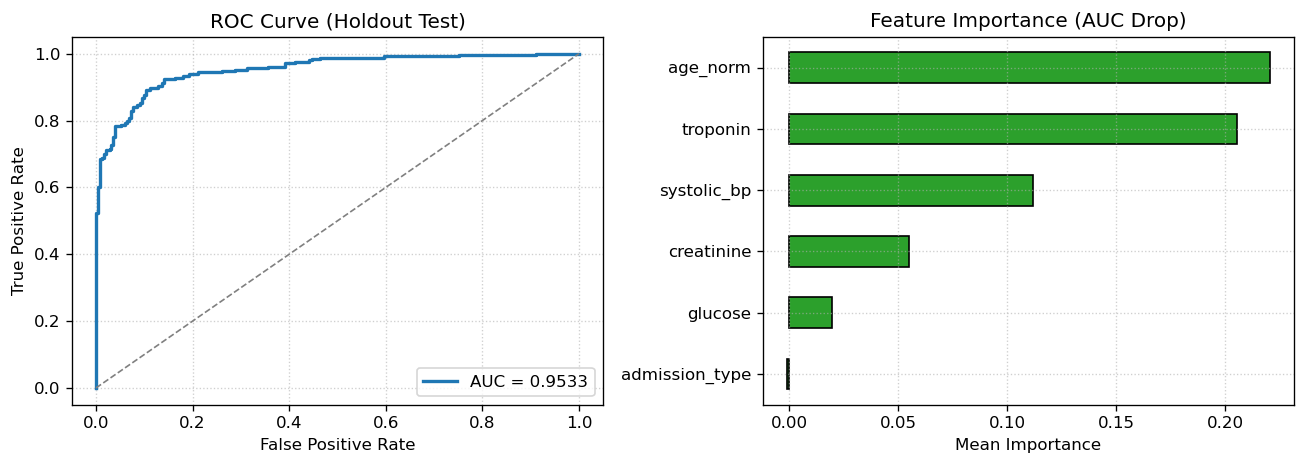

In [20]:
print(f"Templated HTML report saved to '{output_html_path}'.")
display(HTML(rendered_html))